# Figure 1: the data and the PCA basis

(a) The Argo profiles paired with a SWOT overpass (the training set) and the SWOT tracks; (b) the Cal/Val moorings
and S2 over the SWOT SSHA of the 8 May 2023 overpass; (c) the hourly density record at S2 with its mixed-layer depth;
(d) one mooring's profiles projected on 2 and 4 modes of the basis; (e-g) the basis: the mean anomaly, the four
leading modes and the cumulative variance. The basis is fit on the density anomalies of the pretraining record.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
from swot2argo import data, models, evaluate, gradients, plots
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
T = data.tests()

In [2]:
pairs, hist = data.pairs(), data.history()
print(pairs); print(hist)
for nm, S in T.items(): print(f"{nm:9s} n = {S.n}")

<Samples 'pairs': n=424; dens/clim (n, 40); time, lat, lon, ssh_swot, ssh_duacs, sst, mdt, wmo, cycle, dt_h, sss, bathy, era5_b0_7, era5_b0_30, era5_b0_60, era5_ustar3_7, era5_ustar3_30, era5_ustar3_60>
<Samples 'history': n=14448; dens/clim (n, 40); time, lat, lon, ssh_duacs, sst, mdt, wmo, cycle, sss, bathy, era5_b0_7, era5_b0_30, era5_b0_60, era5_ustar3_7, era5_ustar3_30, era5_ustar3_60>
moorings  n = 1546
gliders   n = 784
s2        n = 33


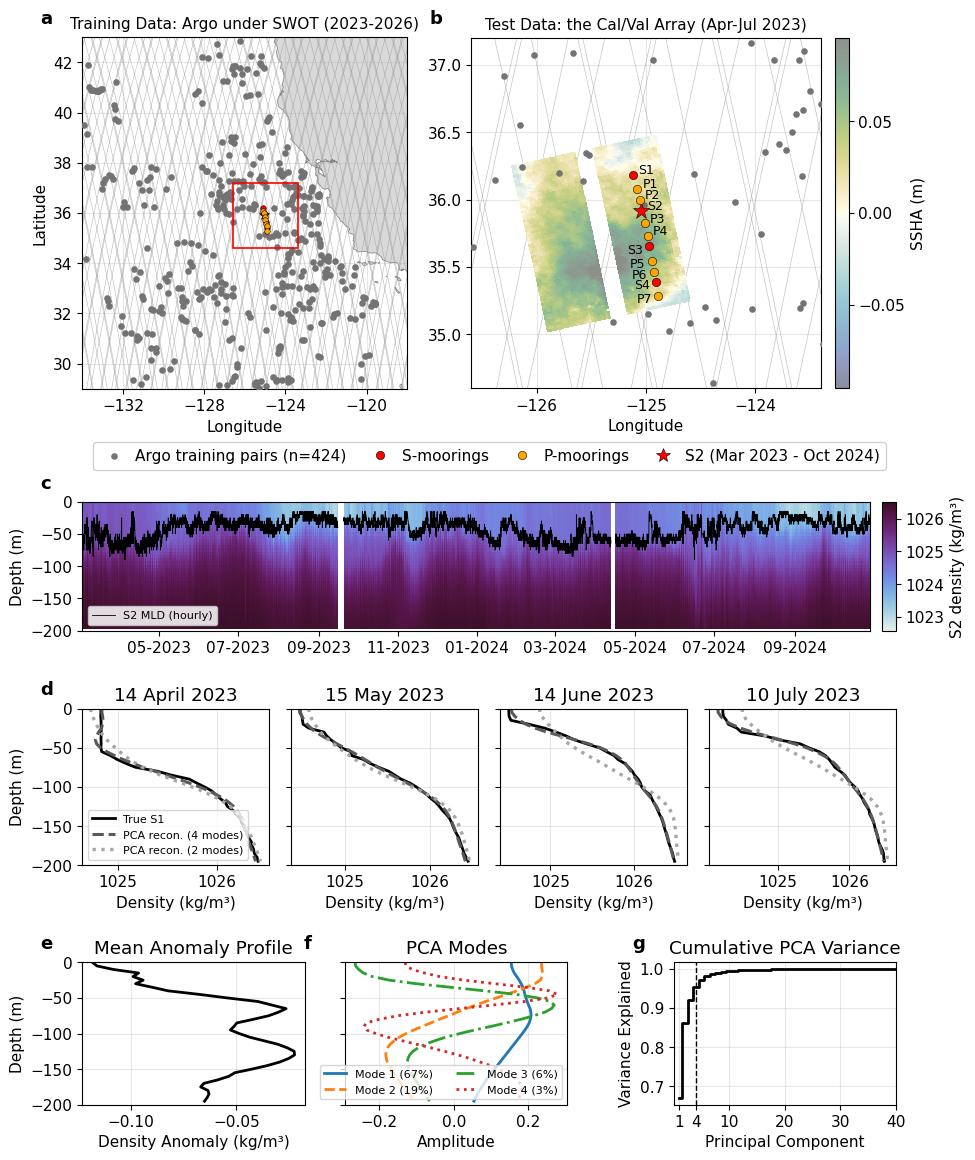

In [3]:
fig = plots.overview(T, hist.anom, "swath_20230508_13.npz"); plt.show()

## The numbers the text quotes

Variance explained by the leading modes, in the Argo record and in the test profiles projected on the same basis;
the depth of the mode-1 maximum; the correlation of the mode-1 coefficient with the SWOT SSHA over the training pairs.

In [4]:
tgt = models.Target(4).fit(hist.anom)
def explained(anom):
    a = anom - tgt.mean
    return 1 - ((a - a @ tgt.modes.T @ tgt.modes) ** 2).sum() / (a ** 2).sum()
print("variance explained by the first 4 modes:", {nm: round(explained(S.anom), 3) for nm, S in [("argo", hist)] + list(T.items())})
print("modes 1-4:", np.round(100 * tgt.explained[:4]).astype(int), "% of the Argo anomaly variance; mode 1 maximum at",
      f"{data.DEPTH[np.argmax(np.abs(tgt.modes[0]))]:.0f} m")
a1 = tgt.encode(pairs.anom)[:, 0]
print("correlation of the mode-1 coefficient with SWOT SSHA over the pairs:", round(np.corrcoef(a1, pairs.ssh_swot)[0, 1], 2))

variance explained by the first 4 modes: {'argo': 0.954, 'moorings': 0.965, 'gliders': 0.97, 's2': 0.963}
modes 1-4: [67 19  6  3] % of the Argo anomaly variance; mode 1 maximum at 75 m
correlation of the mode-1 coefficient with SWOT SSHA over the pairs: -0.74
